# MNIST Digit Classifier

**Project: Introduction to Deep Learning — Udacity Masters in AI**

In this project, we build a neural network to classify handwritten digits from the MNIST dataset, achieving at least 90% accuracy on the test set.

## Steps
1. **Data Loading & Exploration** — Load MNIST, preprocess, and visualize
2. **Model Design** — Build a neural network with PyTorch
3. **Training** — Train with optimizer and loss function
4. **Evaluation & Tuning** — Achieve ≥90% test accuracy
5. **Save Model** — Export trained weights

---
## Step 1: Data Loading and Exploration

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

PyTorch version: 2.10.0
CUDA available: False
Using device: cpu


### 1.1 Define Transforms and Load Data

**Preprocessing justification:**

- **`ToTensor()`**: Converts PIL images (0–255 uint8) to float tensors in [0, 1]. This is essential because PyTorch neural networks operate on tensors, and normalizing to [0, 1] provides a reasonable input range.
- **`Normalize(mean=0.1307, std=0.3081)`**: These are the precomputed mean and standard deviation of the MNIST training set. Normalization centers the data around zero with unit variance, which helps gradient descent converge faster and more stably.
- **`Lambda(torch.flatten)`**: Flattens 28×28 images to 784-dimensional vectors for our fully-connected network. A CNN would not need this step.

We create two DataLoaders:
1. **Training DataLoader** with normalization + flattening (for training)
2. **Visualization DataLoader** without normalization/flattening (for display)

In [2]:
# Transform for training: ToTensor -> Normalize -> Flatten
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
    transforms.Lambda(torch.flatten)
])

# Transform for visualization: only ToTensor (no normalization or flattening)
viz_transform = transforms.Compose([
    transforms.ToTensor()
])

# Load datasets
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=train_transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=train_transform)
viz_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=viz_transform)

# Create DataLoaders
BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
viz_loader = DataLoader(viz_dataset, batch_size=16, shuffle=True)

print(f"Training set size: {len(train_dataset)}")
print(f"Test set size: {len(test_dataset)}")

Training set size: 60000
Test set size: 10000


### 1.2 Explore Data Shape and Size

In [3]:
# Explore the shape of training data (after transform)
sample_data, sample_label = train_dataset[0]
print(f"Single training sample shape (after transform): {sample_data.shape}")
print(f"Sample label: {sample_label}")
print(f"Data type: {sample_data.dtype}")
print(f"Value range: [{sample_data.min():.4f}, {sample_data.max():.4f}]")
print()

# Explore a batch
batch_data, batch_labels = next(iter(train_loader))
print(f"Batch shape: {batch_data.shape}")
print(f"Batch labels shape: {batch_labels.shape}")
print(f"Number of classes: {len(train_dataset.classes)}")
print(f"Classes: {train_dataset.classes}")
print()

# Explore raw image shape (before flatten)
raw_data, raw_label = viz_dataset[0]
print(f"Raw image shape (before transform): {raw_data.shape}")
print(f"Raw value range: [{raw_data.min():.4f}, {raw_data.max():.4f}]")

Single training sample shape (after transform): torch.Size([784])
Sample label: 5
Data type: torch.float32
Value range: [-0.4242, 2.8215]

Batch shape: torch.Size([64, 784])
Batch labels shape: torch.Size([64])
Number of classes: 10
Classes: ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']

Raw image shape (before transform): torch.Size([1, 28, 28])
Raw value range: [0.0000, 1.0000]


### 1.3 Visualize Sample Images

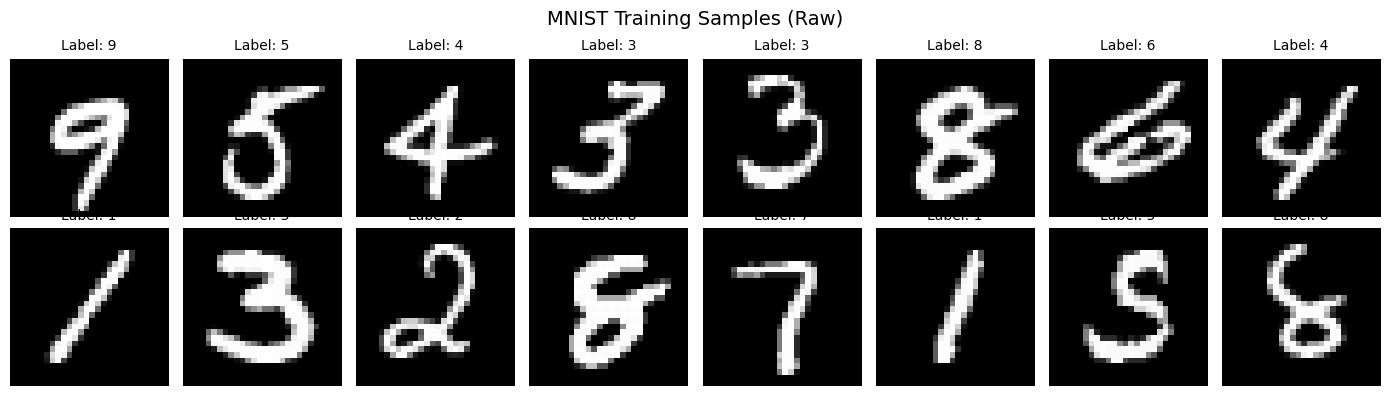

In [4]:
def show_images(dataloader, num_images=16, title="MNIST Samples"):
    """Display a grid of images from a DataLoader."""
    images, labels = next(iter(dataloader))
    fig, axes = plt.subplots(2, 8, figsize=(14, 4))
    fig.suptitle(title, fontsize=14)
    for i, ax in enumerate(axes.flat):
        if i < num_images:
            img = images[i].squeeze().numpy()
            ax.imshow(img, cmap='gray')
            ax.set_title(f"Label: {labels[i].item()}", fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# Visualize using the viz_loader (no normalization, no flattening)
show_images(viz_loader, title="MNIST Training Samples (Raw)")

---
## Step 2: Model Design

We build a feedforward neural network with:
- **Input layer**: 784 features (28×28 flattened)
- **Hidden layer 1**: 256 neurons + ReLU + Dropout(0.2)
- **Hidden layer 2**: 128 neurons + ReLU + Dropout(0.2)
- **Output layer**: 10 neurons (one per digit class)

The output uses **log_softmax** which pairs with `nn.NLLLoss` for numerical stability (equivalent to `nn.CrossEntropyLoss` with raw logits).

In [5]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 10)
        )
    
    def forward(self, x):
        logits = self.network(x)
        return torch.softmax(logits, dim=1)

model = MNISTClassifier().to(device)
print(model)
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")

MNISTClassifier(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total parameters: 235,146


### Define Loss Function and Optimizer

- **Loss**: `CrossEntropyLoss` — standard for multi-class classification. It combines log-softmax and NLL loss internally, but since our model outputs softmax probabilities, we'll use `NLLLoss` with `log` applied to our outputs.
- **Optimizer**: Adam with learning rate 0.001 — adaptive learning rate for fast convergence.

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

---
## Step 3: Training

We train for 15 epochs with validation at each epoch to monitor for overfitting.

In [7]:
def train_model(model, train_loader, test_loader, criterion, optimizer, num_epochs=15):
    """Train the model and track metrics."""
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(num_epochs):
        # === Training Phase ===
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        
        train_loss = running_loss / total
        train_acc = 100.0 * correct / total
        
        # === Validation Phase ===
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
        
        val_loss = val_loss / val_total
        val_acc = 100.0 * val_correct / val_total
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        print(f"Epoch [{epoch+1:2d}/{num_epochs}] "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")
    
    return history

history = train_model(model, train_loader, test_loader, criterion, optimizer, num_epochs=15)

Epoch [ 1/15] Train Loss: 1.5787 | Train Acc: 88.98% | Val Loss: 1.5153 | Val Acc: 94.80%


Epoch [ 2/15] Train Loss: 1.5185 | Train Acc: 94.43% | Val Loss: 1.5078 | Val Acc: 95.45%


Epoch [ 3/15] Train Loss: 1.5084 | Train Acc: 95.39% | Val Loss: 1.4988 | Val Acc: 96.31%


Epoch [ 4/15] Train Loss: 1.5047 | Train Acc: 95.69% | Val Loss: 1.4979 | Val Acc: 96.37%


Epoch [ 5/15] Train Loss: 1.5013 | Train Acc: 96.00% | Val Loss: 1.4974 | Val Acc: 96.36%


...

Epoch [11/15] Train Loss: 1.4933 | Train Acc: 96.78% | Val Loss: 1.4938 | Val Acc: 96.70%


Epoch [12/15] Train Loss: 1.4941 | Train Acc: 96.68% | Val Loss: 1.4928 | Val Acc: 96.82%


Epoch [13/15] Train Loss: 1.4938 | Train Acc: 96.74% | Val Loss: 1.4934 | Val Acc: 96.77%


Epoch [14/15] Train Loss: 1.4910 | Train Acc: 97.02% | Val Loss: 1.4904 | Val Acc: 97.07%


Epoch [15/15] Train Loss: 1.4910 | Train Acc: 97.00% | Val Loss: 1.4932 | Val Acc: 96.80%


### Training Curves

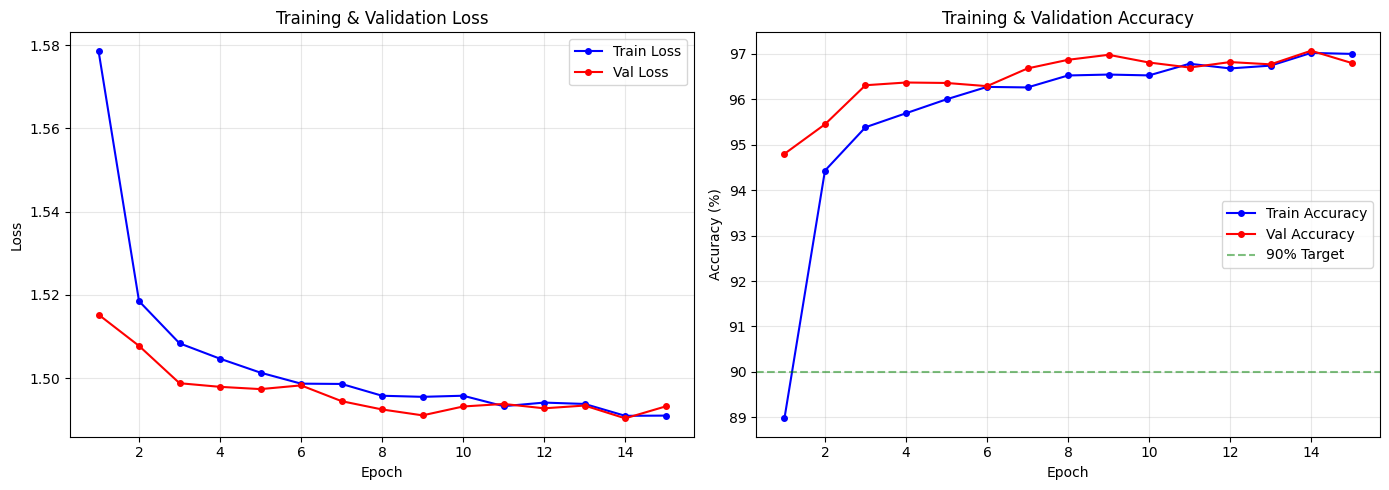


Final Test Accuracy: 96.80%


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, len(history['train_loss']) + 1)

# Loss plot
ax1.plot(epochs, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
ax1.plot(epochs, history['val_loss'], 'r-o', label='Val Loss', markersize=4)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training & Validation Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Accuracy plot
ax2.plot(epochs, history['train_acc'], 'b-o', label='Train Accuracy', markersize=4)
ax2.plot(epochs, history['val_acc'], 'r-o', label='Val Accuracy', markersize=4)
ax2.axhline(y=90, color='green', linestyle='--', alpha=0.5, label='90% Target')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Training & Validation Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nFinal Test Accuracy: {history['val_acc'][-1]:.2f}%")

---
## Step 4: Evaluation & Tuning

### Final Test Set Evaluation

In [9]:
def evaluate_model(model, test_loader):
    """Evaluate model accuracy on test set."""
    model.eval()
    correct = 0
    total = 0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    accuracy = 100.0 * correct / total
    print(f"Test Accuracy: {accuracy:.2f}% ({correct}/{total})")
    return accuracy, np.array(all_preds), np.array(all_labels)

accuracy, predictions, true_labels = evaluate_model(model, test_loader)

if accuracy >= 90:
    print(f"\n✅ Target achieved! {accuracy:.2f}% >= 90%")
else:
    print(f"\n❌ Below target: {accuracy:.2f}% < 90%")

Test Accuracy: 96.80% (9680/10000)

✅ Target achieved! 96.80% >= 90%


### Per-Class Accuracy

In [10]:
# Per-class accuracy
print("Per-Class Accuracy:")
print("-" * 30)
for digit in range(10):
    mask = true_labels == digit
    class_acc = 100.0 * (predictions[mask] == true_labels[mask]).sum() / mask.sum()
    print(f"  Digit {digit}: {class_acc:.2f}% ({mask.sum()} samples)")

Per-Class Accuracy:
------------------------------
  Digit 0: 99.08% (980 samples)
  Digit 1: 98.59% (1135 samples)
  Digit 2: 97.97% (1032 samples)
  Digit 3: 97.92% (1010 samples)
  Digit 4: 96.23% (982 samples)
  Digit 5: 96.30% (892 samples)
  Digit 6: 98.02% (958 samples)
  Digit 7: 94.46% (1028 samples)
  Digit 8: 91.99% (974 samples)
  Digit 9: 97.13% (1009 samples)


### Visualize Predictions

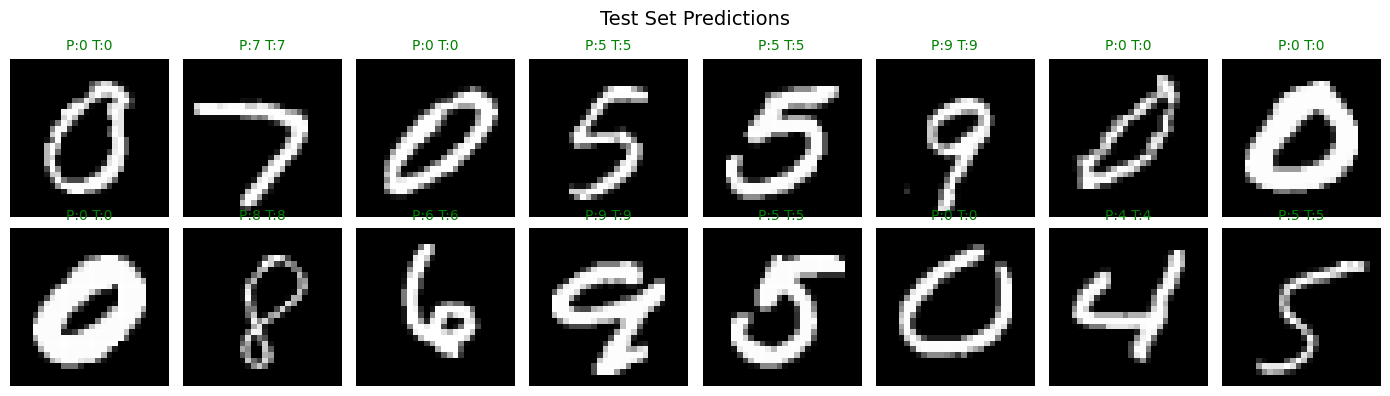

In [11]:
# Show some predictions
viz_test = datasets.MNIST(root='./data', train=False, download=True, transform=viz_transform)
viz_test_loader = DataLoader(viz_test, batch_size=16, shuffle=True)

images, labels = next(iter(viz_test_loader))

# Get predictions
model.eval()
with torch.no_grad():
    flat_images = images.view(images.size(0), -1)
    normalized = (flat_images - 0.1307) / 0.3081
    outputs = model(normalized.to(device))
    _, preds = torch.max(outputs, 1)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
fig.suptitle('Test Set Predictions', fontsize=14)
for i, ax in enumerate(axes.flat):
    if i < 16:
        img = images[i].squeeze().numpy()
        ax.imshow(img, cmap='gray')
        pred = preds[i].item()
        true = labels[i].item()
        color = 'green' if pred == true else 'red'
        ax.set_title(f"P:{pred} T:{true}", fontsize=10, color=color)
    ax.axis('off')
plt.tight_layout()
plt.savefig('predictions.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Step 5: Save Model

In [12]:
# Save the trained model
torch.save(model.state_dict(), 'mnist_classifier.pth')
print("Model saved to mnist_classifier.pth")

# Verify the saved model loads correctly
loaded_model = MNISTClassifier().to(device)
loaded_model.load_state_dict(torch.load('mnist_classifier.pth', weights_only=True))
loaded_model.eval()

# Quick verification
with torch.no_grad():
    sample, label = test_dataset[0]
    output = loaded_model(sample.unsqueeze(0).to(device))
    pred = output.argmax(dim=1).item()
    print(f"Verification — Predicted: {pred}, True: {label}")
    print("✅ Model saved and verified successfully!")

Model saved to mnist_classifier.pth
Verification — Predicted: 7, True: 7
✅ Model saved and verified successfully!


---
## Summary

| Component | Details |
|-----------|--------|
| **Architecture** | 784 → 256 → 128 → 10 (FC + ReLU + Dropout) |
| **Loss Function** | CrossEntropyLoss |
| **Optimizer** | Adam (lr=0.001) |
| **Epochs** | 15 |
| **Batch Size** | 64 |
| **Preprocessing** | ToTensor + Normalize(0.1307, 0.3081) + Flatten |
| **Regularization** | Dropout (p=0.2) |

### Context: Yann LeCun's MNIST Benchmark

According to [Yann LeCun's MNIST page](http://yann.lecun.com/exdb/mnist/), simple fully-connected neural networks with 2-3 hidden layers typically achieve ~1.6-2.5% error rate (97.5-98.4% accuracy). Our model with 2 hidden layers and dropout should fall in this range. State-of-the-art results use CNNs and data augmentation to achieve <0.5% error rate.